# Phase 9 — Interpretation, Error Analysis and End-to-End Inference Check

**Purpose.** (a) Explain what the model relies on and where it still fails, using the validation set with the frozen Phase 8 rule (global threshold);
(b) prove that the packaged inference script `predict.py` reproduces the validated scores and writes files that pass `validate_submission.py`.
Nothing here changes the model or the threshold — this phase only *reads* validation labels to explain errors.

**Sections:** 1 Load → 2 Feature importance (permutation) → 3 False positives → 4 Missed matches → 5 Entities with a single match → 6 End-to-end check → 7 Summary

In [1]:
import os, sys, json, pickle, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import average_precision_score
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import eval_utils as EU
import pair_features as PF

ROOT = "../../../"; INTERIM = ROOT + "dataset/interim"
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 48)
cfgT = json.load(open("threshold_config.json"))["decision"]; THR = cfgT["threshold"]
FEATS = json.load(open("feature_list.json"))["final_features"]
cv = pd.read_pickle(INTERIM + "/candidates_val.pkl"); sv = pd.read_pickle(INTERIM + "/val_scores.pkl")
Fv = pd.read_pickle(INTERIM + "/features_val.pkl")[FEATS]
assert (cv.s1_id.values == sv.s1_id.values).all() and len(Fv) == len(cv)
P4 = pickle.load(open(INTERIM + "/phase4_truth_and_queries.pkl", "rb"))
ents = cv.s1_id.unique().tolist(); tv = P4["truth"]["val"]; tv = tv[tv.s1_id.isin(set(ents))]
ntrue = tv.groupby("s1_id").size()
y = cv.label.values; p = sv.score.values; pred = (p >= THR)
mac, fe = EU.macro_f05(ents, ntrue, cv.s1_id.values, y, pred.astype(int))
print(f"threshold {THR} | validation macro F0.5 {mac:.4f} | pairs {len(cv):,} | FP {int((pred&(y==0)).sum()):,} | FN (retrieved) {int((~pred&(y==1)).sum()):,} | TP {int((pred&(y==1)).sum()):,}")

threshold 0.7 | validation macro F0.5 0.9508 | pairs 227,888 | FP 173 | FN (retrieved) 885 | TP 18,332


## 2. What does the model use? — permutation importance
Shuffle one feature (within the validation set) and measure the drop in PR-AUC; 3 repeats. Features in the same group are also shuffled together,
because correlated features hide each other's importance when shuffled one at a time.

baseline PR-AUC 0.9976
a_tset               0.0157
n_ratio              0.0078
a_num_jacc           0.0077
n_unm_c_max_idf      0.0042
n_unm_s_max_idf      0.0019
n_suf_conflict       0.0019
a_idf_jacc           0.0018
n_unm_c_idf          0.0015
n_idf_jacc           0.0015
a_tfidf_cos__rank    0.0014
n_partial            0.0012
n_len_c              0.0012
n_unm_c              0.0010
c_nonlatin           0.0008
n_soft_c             0.0008



group-wise permutation drop in PR-AUC:
addr_basic         0.1870
name_structural    0.0499
name_basic         0.0321
addr_numbers       0.0149
relative           0.0091


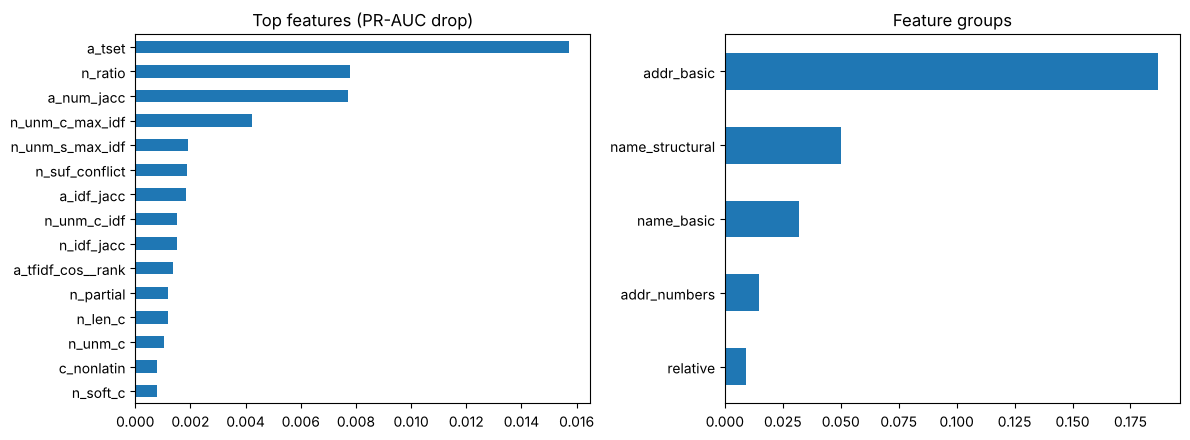

In [2]:
model = joblib.load("model_pair.joblib"); X = Fv.values.astype(np.float32); base = average_precision_score(y, p)
rng = np.random.default_rng(42)
def drop(cols, reps=3):
    ds = []
    for _ in range(reps):
        Xp = X.copy()
        for c in cols: Xp[:, c] = rng.permutation(Xp[:, c])
        ds.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return float(np.mean(ds))
imp = pd.Series({f: drop([i]) for i, f in enumerate(FEATS)}).sort_values(ascending=False)
print(f"baseline PR-AUC {base:.4f}"); print(imp.head(15).round(4).to_string())
grp = {g: [i for i, f in enumerate(FEATS) if f in cols] for g, cols in PF.GROUPS.items()}
gimp = pd.Series({g: drop(ix) for g, ix in grp.items() if ix}).sort_values(ascending=False)
print("\ngroup-wise permutation drop in PR-AUC:"); print(gimp.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); imp.head(15)[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Top features (PR-AUC drop)")
gimp[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Feature groups"); plt.tight_layout(); plt.show()

## 3. False positives — wrong pairs the model accepts
F0.5 is precision-heavy, so these cost the most. Categorise by what the candidate looks like.

In [3]:
d = cv.assign(p=p, pred=pred).join(Fv[["n_ratio", "n_tfidf_cos", "a_tsort", "a_c_missing", "a_num_conflict", "n_suf_conflict"]])
fp = d[d.pred & (d.label == 0)].copy(); print(f"{len(fp):,} false positives ({len(fp)/max(d.pred.sum(),1):.2%} of predictions)")
def cat(r):
    if r.a_c_missing > 0: return "candidate address missing"
    if r.n_ratio >= 0.9 and r.a_tsort < 0.6: return "near-identical name, different address"
    if r.n_ratio >= 0.9: return "near-identical name, similar address (likely duplicate/chain)"
    return "other"
fp["cause"] = fp.apply(cat, axis=1); print(fp.cause.value_counts().to_string()); print("\nby country:", fp.country.value_counts().to_dict(), "| by source:", fp.cand_id.str[:2].value_counts().to_dict())
print("\nconfident false positives (p >= 0.95):"); print(fp.sort_values("p", ascending=False)[["s1_name", "c_name", "s1_addr", "c_addr", "p"]].head(8).to_string(index=False))

173 false positives (0.93% of predictions)
cause
other                                                            101
candidate address missing                                         46
near-identical name, similar address (likely duplicate/chain)     22
near-identical name, different address                             4

by country: {'US': 87, 'India': 86} | by source: {'S2': 105, 'S3': 68}

confident false positives (p >= 0.95):
                      s1_name                          c_name                                                                               s1_addr                                                                    c_addr        p
      Garcia, Lisetta C., DDS        Garcia, Lisetta C., BDDS                                                   9109 Windrush Drive, Fort Worth, TX                                         9109. WINDRUSH DR, FORT WORTH, TX 0.998857
                         Onyx                         Onyxwex                                        

## 4. Missed matches
Two kinds: **not retrieved** (never reached the classifier — a recall limit of Phase 3/4) and **retrieved but rejected** (below the threshold).

In [4]:
n_all = len(tv); n_ret = int(y.sum()); n_tp = int((pred & (y == 1)).sum())
print(f"true matches {n_all:,} | retrieved {n_ret:,} ({n_ret/n_all:.1%}) | accepted {n_tp:,} ({n_tp/n_all:.1%}) | lost at retrieval {n_all-n_ret:,} | lost at threshold {n_ret-n_tp:,}")
fn = d[(~d.pred) & (d.label == 1)].copy(); fn["why"] = np.select([fn.a_c_missing > 0, fn.n_tfidf_cos < 0.5, fn.a_tsort < 0.5], ["candidate address missing", "names differ a lot", "addresses differ a lot"], "borderline score")
print(fn.why.value_counts().to_string()); print("by country:", fn.country.value_counts().to_dict(), "| by source:", fn.cand_id.str[:2].value_counts().to_dict())
print("\nexamples of rejected true matches:"); print(fn.sort_values("p", ascending=False)[["s1_name", "c_name", "s1_addr", "c_addr", "p"]].head(8).to_string(index=False))
found = tv.set_index(["s1_id", "cand_id"]).found if "found" in tv.columns else None
if found is not None:
    miss = tv[~tv.found]; print("\nunretrieved true matches by source:", miss.cand_id.str[:2].value_counts().to_dict(), "| by country:", miss.s1_id.map(cv.drop_duplicates("s1_id").set_index("s1_id").country).value_counts().to_dict())

true matches 20,689 | retrieved 19,217 (92.9%) | accepted 18,332 (88.6%) | lost at retrieval 1,472 | lost at threshold 885
why
candidate address missing    391
borderline score             236
names differ a lot           235
addresses differ a lot        23
by country: {'US': 523, 'India': 362} | by source: {'S2': 464, 'S3': 421}

examples of rejected true matches:
                        s1_name                                    c_name                                                                                   s1_addr                                                                                                 c_addr        p
             Metro Charities IV                          METRO CAHIRTS IV                                                505 Piccadilly Row, Unit 47, Nashville, TN                                                                      485 PICCADILLY ROW, NASHVILLE, TN 0.698759
Sun Investments Private Limited സൺ ഇൻവെസ്റ്റ്മെന്റ്സ് പ്രൈവറ്റ് ലിമിറ്റഡ്      

## 5. Why entities with exactly one true match score lower
With one true match, missing it gives F0.5 = 0 (nothing to average out), and any wrong extra match halves precision.

In [5]:
nt = ntrue.reindex(ents).fillna(0).astype(int); e1 = pd.DataFrame({"f": fe.values}, index=fe.index); e1["n"] = nt.values
g = pd.DataFrame({"tp": (pred & (y == 1)), "np": pred, "q": cv.s1_id.values}).groupby("q").sum(); e1 = e1.join(g)
one = e1[e1.n == 1]; retrieved = cv[cv.label == 1].groupby("s1_id").size().reindex(one.index).fillna(0) > 0
print(f"{len(one)} entities with 1 true match: mean F0.5 {one.f.mean():.3f}")
print(f"  true match not retrieved: {(~retrieved).sum()} | retrieved but rejected: {int(((one.tp == 0) & retrieved).sum())} | found with extra wrong match: {int(((one.tp == 1) & (one.np > 1)).sum())} | perfect: {int(((one.tp == 1) & (one.np == 1)).sum())}")

337 entities with 1 true match: mean F0.5 0.881
  true match not retrieved: 25 | retrieved but rejected: 11 | found with extra wrong match: 9 | perfect: 292


## 6. End-to-end check of `predict.py`
`predict.py` was run on 300 validation queries as if they were a test set (their S1 records as `test_source1.tsv`; the train S2/S3 files as the pool; `sim_test/` -> `sim_out/`).
The scores it produced must equal the cached Phase 7 validation scores for the same pairs, and the output files must pass the official validator.

In [6]:
SIM = ROOT + "sim_out"
if os.path.exists(SIM + "/_work/scores.pkl"):
    ss = pd.read_pickle(SIM + "/_work/scores.pkl").merge(sv.assign(cand_id=cv.cand_id.values).rename(columns={"score": "ref"}), on=["s1_id", "cand_id"], how="outer", indicator=True)
    both = ss[ss._merge == "both"]; sub = ss[ss.s1_id.isin(set(ss[ss._merge != "right_only"].s1_id))]
    print(f"pairs from predict.py: {int((ss._merge != 'right_only').sum()):,} | in cached table (same queries): {int((sub._merge != 'left_only').sum()):,} | only in predict.py: {int((sub._merge == 'left_only').sum())} | only in cache: {int((sub._merge == 'right_only').sum())}")
    print(f"max |score difference| on shared pairs: {np.abs(both.score - both.ref).max():.2e}")
    print(subprocess.run([sys.executable, ROOT + "validate_submission.py", "--matching", SIM + "/matching_results.tsv", "--candidate", SIM + "/candidate_pairs.tsv", "--test-dir", ROOT + "sim_test"], capture_output=True, text=True).stdout[-900:])
else:
    print("run first:  python predict.py --test-dir ../../../sim_test --out-dir ../../../sim_out")

pairs from predict.py: 11,495 | in cached table (same queries): 11,495 | only in predict.py: 0 | only in cache: 0
max |score difference| on shared pairs: 2.98e-08
ML Challenge 2026 — submission validator
  test dir: ../../../sim_test
  required S1 entities: 300
  matching_results.tsv: 300 rows (22 empty, 278 non-empty).
  candidate_pairs.tsv: 300 rows (0 empty, 300 non-empty).

PASS — no blocking issues found. Safe to submit.



## 7. Summary

In [7]:
summary = {"val_macro_f05": round(mac, 4), "threshold": THR, "false_positives": int(len(fp)), "fp_causes": fp.cause.value_counts().to_dict(),
           "true_matches": int(n_all), "retrieved": n_ret, "accepted": n_tp, "top_features": imp.head(8).round(4).to_dict(), "group_importance": gimp.round(4).to_dict()}
json.dump(summary, open("phase9_summary.json", "w"), indent=2); print(json.dumps(summary, indent=2))

{
  "val_macro_f05": 0.9508,
  "threshold": 0.7,
  "false_positives": 173,
  "fp_causes": {
    "other": 101,
    "candidate address missing": 46,
    "near-identical name, similar address (likely duplicate/chain)": 22,
    "near-identical name, different address": 4
  },
  "true_matches": 20689,
  "retrieved": 19217,
  "accepted": 18332,
  "top_features": {
    "a_tset": 0.0157,
    "n_ratio": 0.0078,
    "a_num_jacc": 0.0077,
    "n_unm_c_max_idf": 0.0042,
    "n_unm_s_max_idf": 0.0019,
    "n_suf_conflict": 0.0019,
    "a_idf_jacc": 0.0018,
    "n_unm_c_idf": 0.0015
  },
  "group_importance": {
    "addr_basic": 0.187,
    "name_structural": 0.0499,
    "name_basic": 0.0321,
    "addr_numbers": 0.0149,
    "relative": 0.0091
  }
}
